In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('Salary_Data_Linear_Regression.csv')

print(df.head())

Saving Salary_Data_Linear_Regression.csv to Salary_Data_Linear_Regression.csv
   YearsExperience  Salary
0              1.1   39343
1              1.3   46205
2              1.5   37731
3              2.0   43525
4              2.2   39891


In [3]:
print(df.shape)

print(df.info())

print(df.describe())

print(df.isnull().sum())

(30, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 612.0 bytes
None
       YearsExperience         Salary
count        30.000000      30.000000
mean          6.093333   83378.766667
std           3.346221   31740.695784
min           1.100000   37731.000000
25%           3.325000   56778.750000
50%           5.600000   82225.500000
75%           8.925000  111834.000000
max          12.000000  139000.000000
YearsExperience    0
Salary             0
dtype: int64


In [4]:
median_salary = df['Salary'].median()

df['SalaryCategory'] = (
    df['Salary'] >= median_salary
).astype(int)

print(df.head(10))

   YearsExperience  Salary  SalaryCategory
0              1.1   39343               0
1              1.3   46205               0
2              1.5   37731               0
3              2.0   43525               0
4              2.2   39891               0
5              2.9   56642               0
6              3.0   60150               0
7              3.2   54445               0
8              3.7   57189               0
9              3.9   63218               0


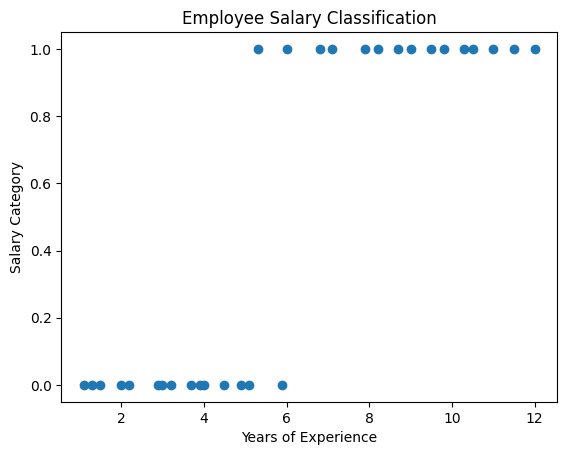

In [5]:
plt.scatter(
    df['YearsExperience'],
    df['SalaryCategory']
)

plt.xlabel('Years of Experience')
plt.ylabel('Salary Category')

plt.title('Employee Salary Classification')

plt.show()

In [6]:
X = df[['YearsExperience']]

y = df['SalaryCategory']

print("Input:")
print(X.head())

print("Output:")
print(y.head())

Input:
   YearsExperience
0              1.1
1              1.3
2              1.5
3              2.0
4              2.2
Output:
0    0
1    0
2    0
3    0
4    0
Name: SalaryCategory, dtype: int64


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", len(X_train))
print("Testing:", len(X_test))

Training: 24
Testing: 6


In [8]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [9]:
model = LogisticRegression()

In [10]:
model.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


In [11]:
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("Predicted Values:")
print(y_pred)

Actual Values:
[1 0 1 0 1 0]
Predicted Values:
[1 0 1 0 1 0]


In [12]:
y_probability = model.predict_proba(X_test)

print(y_probability)

[[0.12459396 0.87540604]
 [0.86441003 0.13558997]
 [0.02082314 0.97917686]
 [0.92316056 0.07683944]
 [0.36457853 0.63542147]
 [0.65665718 0.34334282]]


In [13]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("Precision:", precision)

print("Recall:", recall)

print("F1 Score:", f1)

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


[[3 0]
 [0 3]]


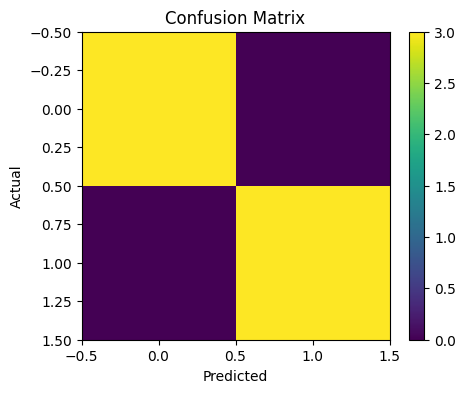

In [14]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

plt.figure(figsize=(5, 4))

plt.imshow(cm)

plt.title('Confusion Matrix')

plt.xlabel('Predicted')

plt.ylabel('Actual')

plt.colorbar()

plt.show()

In [15]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



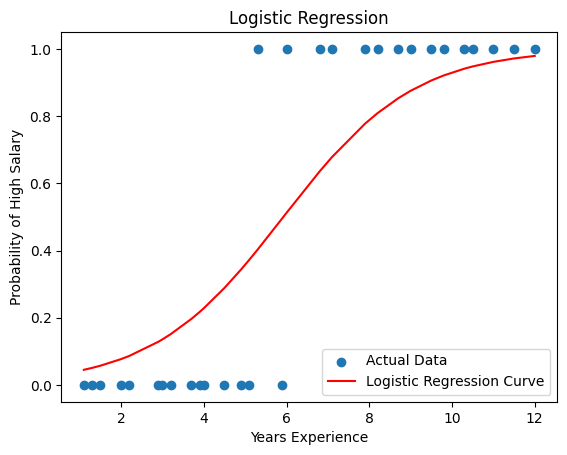

In [16]:
X_original = df[['YearsExperience']]

X_scaled = scaler.transform(X_original)

probability = model.predict_proba(X_scaled)[:, 1]

plt.scatter(
    df['YearsExperience'],
    df['SalaryCategory'],
    label='Actual Data'
)

plt.plot(
    df['YearsExperience'],
    probability,
    color='red',
    label='Logistic Regression Curve'
)

plt.xlabel('Years Experience')

plt.ylabel('Probability of High Salary')

plt.title('Logistic Regression')

plt.legend()

plt.show()

In [17]:
experience = [[5]]

experience_scaled = scaler.transform(experience)

prediction = model.predict(experience_scaled)

probability = model.predict_proba(experience_scaled)

if prediction[0] == 1:
    print("High Salary")
else:
    print("Low Salary")

print("Probability:", probability[0])

Low Salary
Probability: [0.64223211 0.35776789]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [18]:
import pickle

with open('logistic_model.pkl', 'wb') as file:
    pickle.dump(model, file)

with open('scaler.pkl', 'wb') as file:
    pickle.dump(scaler, file)

print("Model saved successfully")

Model saved successfully


In [19]:
with open('logistic_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

with open('scaler.pkl', 'rb') as file:
    loaded_scaler = pickle.load(file)

new_data = [[7]]

new_data_scaled = loaded_scaler.transform(new_data)

result = loaded_model.predict(new_data_scaled)

print("Prediction:", result)

Prediction: [1]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
